# Mobile Games A/B Testing - Cookie Cats

## Introduction

### Overview

### Goal of the analysis

The goal of this analysis is to decide if the placement of the progression gate significantly impacts player retention and engagement.

Questions to analyse:
1. Does gate placement at level 40 (gate_40) lead to higher 1-day and 7-day retention rates compared to level 30 (gate_30)?
2. Does gate placement affect the total number of game rounds (sum_gamerounds) played in the first 14 days?

### Target metric

- 1-day and 7-day retention rate (measuring days after installation)
- number of game rounds played by a player within the first 14 days after installation

### Calculations

#### 1. Data overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

In [2]:
df = pd.read_csv("cookie_cats.csv")
df.head(5)

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [3]:
df.shape

(90189, 5)

In [4]:
df.isna().sum()

userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

In [5]:
df.duplicated().sum()

0

In [6]:
print(f"Number of users: {df['userid'].nunique()}")

Number of users: 90189


In [7]:
print(f"Number of versions: {df['version'].nunique()}")

Number of versions: 2


In [8]:
df['sum_gamerounds'].describe()

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

In [9]:
df.groupby('version')['sum_gamerounds'].agg(["count", "median", "mean", "std", "max"])

,count,median,mean,std,max
version,,,,,
gate_30,44700,17.0,52.456264,256.716423,49854
gate_40,45489,16.0,51.298776,103.294416,2640


- game rounds data is not normally distributed, right-skewed for both gate versions, because the mean is larger than the median.
- standart deviation for gate_30 is 2.5 times larger than for gate_40, this shows a greater variability in the gate_30 group
- maximum value for gate_30 is much higher than for gate_40 which can indicate outliers

In [12]:
def histogram(df, col, group_col, group_1, group_2, bins=50, figsize=(12,6)):
    """
    Creates a histogram.

    Parameters
    data_df : pandas.DataFrame
        Survey data with 'questiontext' (used as title) and 'AnswerText' (responses) columns.
    bins : int
        Number of bins for the histogram.
    figsize : tuple of floats, optional
        Figure size (width, height) in inches. Default is (4, 4). Only used if ax is None.
    ax : matplotlib.axes.Axes, optional
        Axes to plot on. If None, creates new figure. Default is None.
    """
    plt.figure(figsize=figsize)  
    

    plt.subplot(1, 2, 1) 
    df[df[group_col] == group_1][col].hist(bins=bins, edgecolor='black')
    plt.title(f"Distribution of {group_1}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    

    plt.subplot(1, 2, 2)  
    df[df[group_col] == group_2][col].hist(bins=bins, edgecolor='black')
    plt.title(f"Distribution of {group_2}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    plt.tight_layout() 
    plt.show()

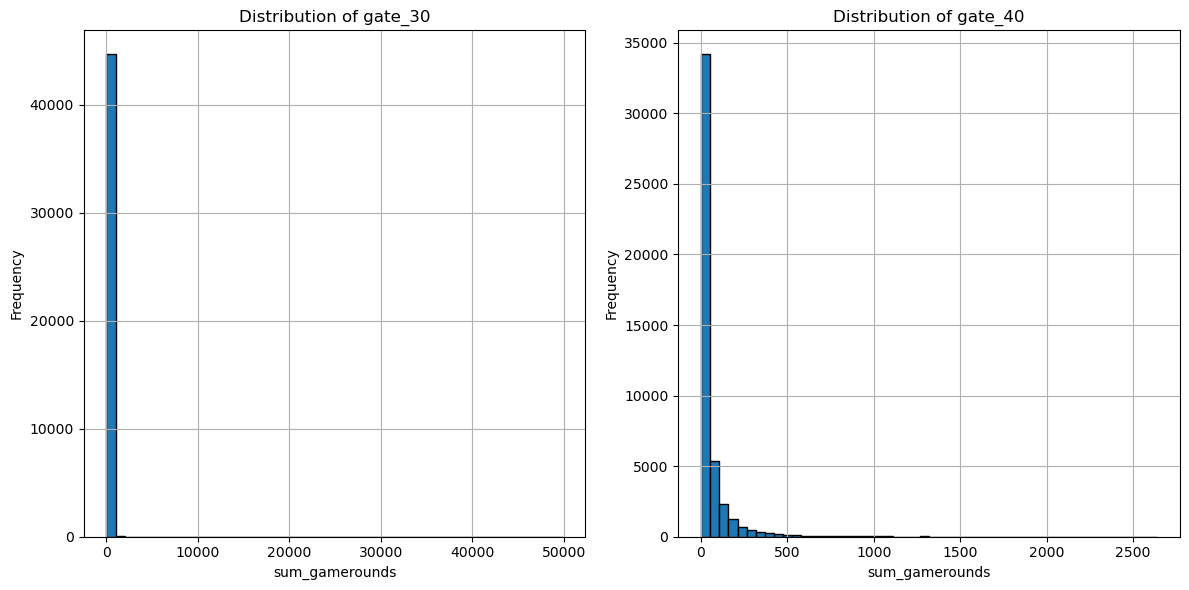

In [13]:
histogram(df, col="sum_gamerounds", 
                group_col="version", group_1="gate_30", 
                group_2="gate_40")



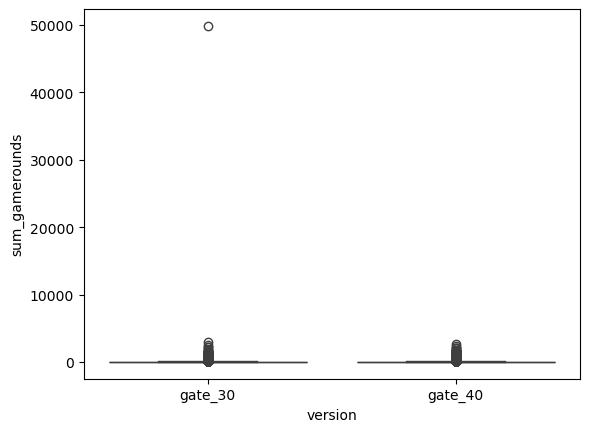

In [14]:
sns.boxplot(data=df, x="version", y="sum_gamerounds")
plt.show()

There is an outlier in the gate_30 group that has to be removed before the statistical analysis.

In [15]:
def remove_outliers(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_cleaned = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    
    return df_cleaned

In [17]:
df_clean = remove_outliers(df, 'sum_gamerounds')

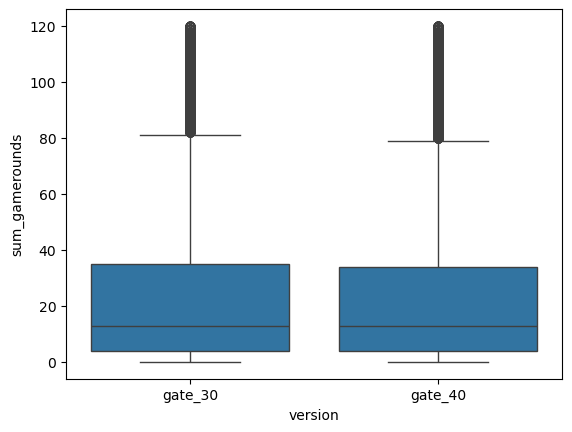

In [18]:
sns.boxplot(data=df, x="version", y="sum_gamerounds")
plt.show()

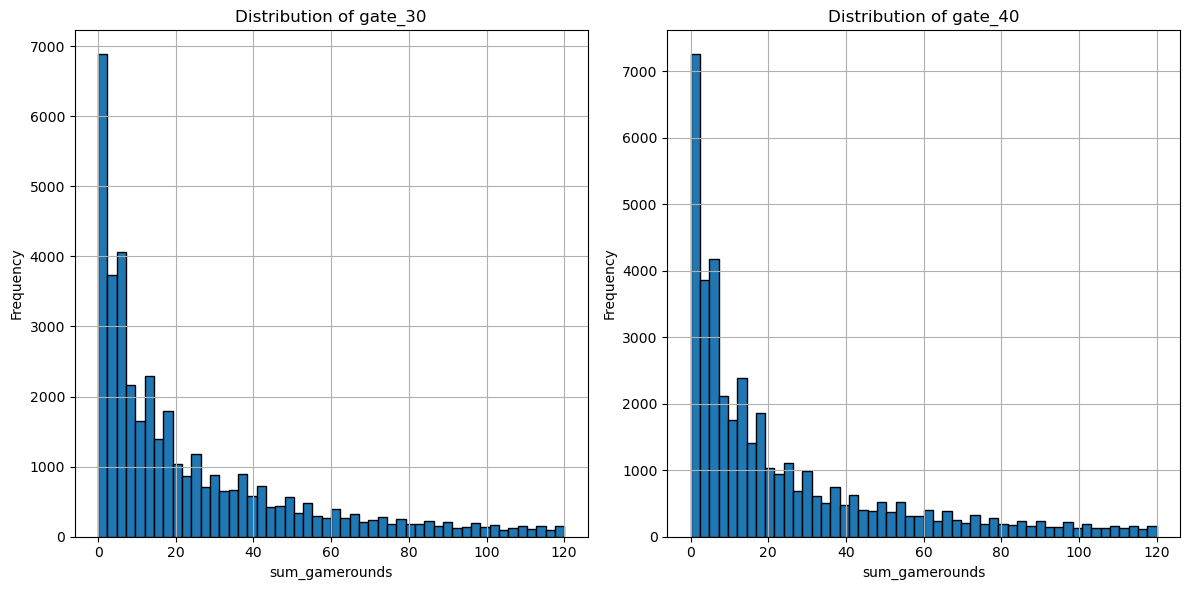

In [19]:
histogram(df, col="sum_gamerounds", 
                group_col="version", group_1="gate_30", 
                group_2="gate_40")

In [37]:
not_active_users = df[df['sum_gamerounds'] == 0]['userid'].count()
not_active_users

3994

In [41]:
not_active_users_perc = not_active_users / df['userid'].count() * 100
not_active_users_perc.round(2)

4.99

- 3994 users installed the game but never played it. It is 4.99% of total users.
- number of active users decrease as the game progresses
- most users play actively in the earliest game rounds

In [42]:
df.groupby(["version", "retention_1"])['sum_gamerounds'].agg(["count", "median", "mean", "std", "max"])

count  median       mean        std  max
version retention_1                                          
gate_30 False        24215     6.0  12.642660  17.491398  120
        True         15423    35.0  41.690786  29.983310  120
gate_40 False        24896     6.0  12.655165  17.972346  120
        True         15478    34.0  42.280656  30.908286  120

In [43]:
df.groupby(["version", "retention_7"])['sum_gamerounds'].agg(["count", "median", "mean", "std", "max"])

count  median       mean        std  max
version retention_7                                          
gate_30 False        34956    11.0  19.681113  23.304905  120
        True          4682    53.0  55.780863  32.212640  120
gate_40 False        35941    10.0  19.889541  23.958521  120
        True          4433    55.0  57.440334  33.618387  120

Retention rates in the group gate_30 and group gate_40 look similar. Statistical tests are needed to see the statistically significant differences.

#### 2. Statistical tests

First hypothesis of the analysis (retention rate):

- H0: there is no statistically significant difference between retention rate for gate_30 and gate_40 groups
- H1: there is a statistically significant difference between retention rate for gate_30 and gate_40 groups

Second hypothesis of the analysis (gamerounds):
- H0: there is no statistically significant difference between game rounds number for gate_30 and gate_40 groups
- H1: there is a statistically significant difference between game rounds number for gate_30 and gate_40 groups

### Decision

### Conclusions